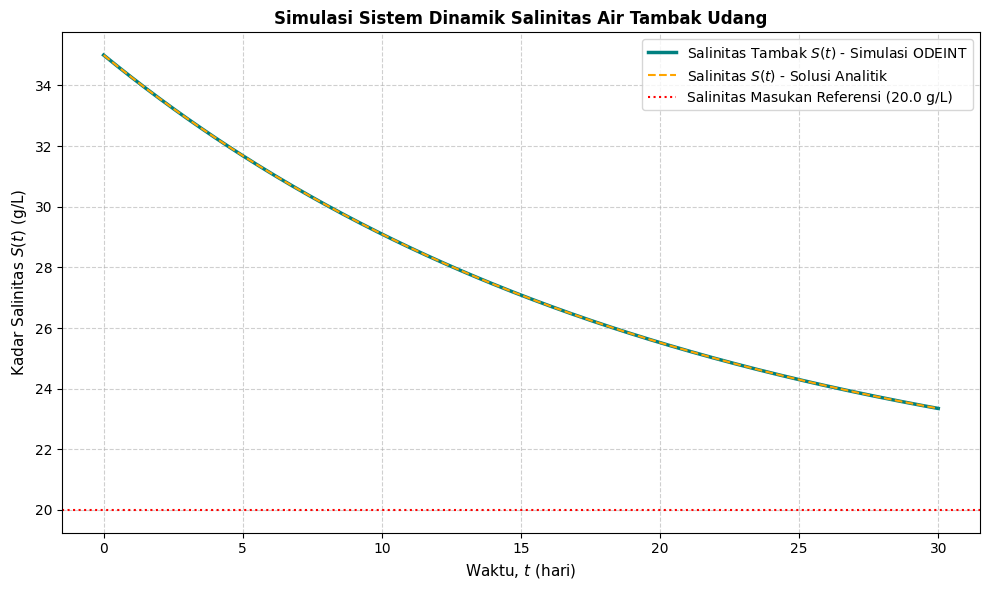

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import odeint

# 1. Parameter Sistem Salinitas Tambak Udang
V = 1000.0      # Volume air tambak (m^3)
Q_in = 50.0     # Laju air masuk (m^3/hari)
Q_out = 50.0    # Laju air keluar (m^3/hari)
S_in = 20.0     # Salinitas air masukan (g/L)
S0 = 35.0       # Salinitas awal di dalam tambak (g/L)

# Rentang waktu simulasi: 0 hingga 30 hari (301 titik data)
t = np.linspace(0, 30, 301)

# 2. Definisi Model Persamaan Diferensial (dS/dt)
void = lambda S, t, Q_in, S_in, Q_out, V: (Q_in * S_in - Q_out * S) / V
def model_salinitas(S, t):
    return (Q_in * S_in - Q_out * S) / V

# 3. Penyelesaian Numerik menggunakan ODEINT
S_simulasi = odeint(model_salinitas, S0, t)

# 4. Solusi Analitik sebagai Pembanding (S(t) = S_in + (S0 - S_in) * exp(-(Q/V)*t))
k_rate = Q_out / V
S_analitik = S_in + (S0 - S_in) * np.exp(-k_rate * t)

# 5. Visualisasi Grafik Pemodelan dan Simulasi
plt.figure(figsize=(10, 6))
plt.plot(t, S_simulasi, label='Salinitas Tambak $S(t)$ - Simulasi ODEINT', color='teal', linewidth=2.5)
plt.plot(t, S_analitik, '--', label='Salinitas $S(t)$ - Solusi Analitik', color='orange', linewidth=1.5)
plt.axhline(S_in, color='red', linestyle=':', linewidth=1.5, label=f'Salinitas Masukan Referensi ({S_in} g/L)')

plt.title('Simulasi Sistem Dinamik Salinitas Air Tambak Udang', fontsize=12, fontweight='bold')
plt.xlabel('Waktu, $t$ (hari)', fontsize=11)
plt.ylabel('Kadar Salinitas $S(t)$ (g/L)', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(loc='best')
plt.tight_layout()
plt.show()